In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, probplot

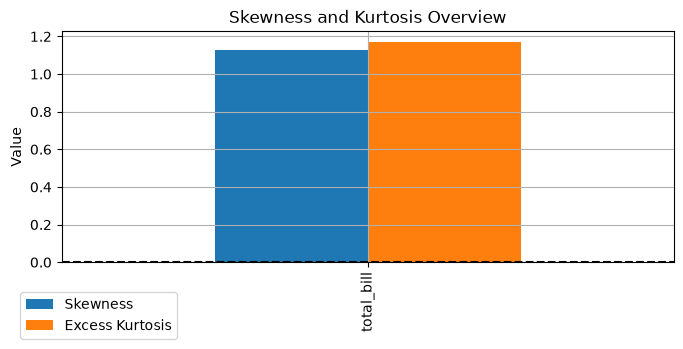

Text(5, 2, 'outliers: \n[40.55, 41.19, 43.11, 44.3, 45.35, 48.17, 48.27, 48.33, 50.81]\nright_lim whisk : 40.0')

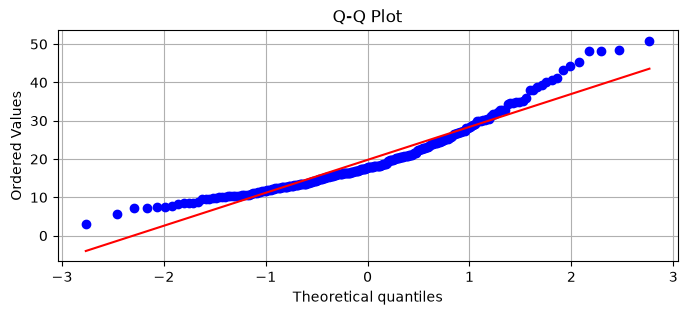

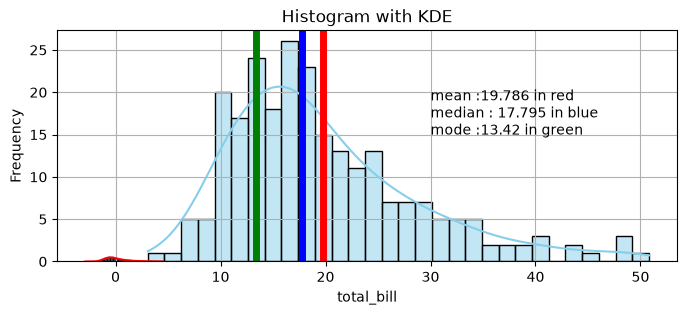

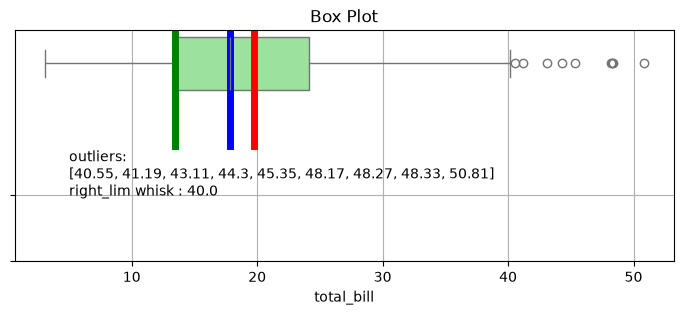

In [52]:

df=sns.load_dataset("tips")
# Select the total_bill column
total_bill = df['total_bill']

# Calculate skewness and kurtosis
summary = pd.DataFrame({
                        'Skewness':          [skew(total_bill) ],
                        'Excess Kurtosis':   [kurtosis(total_bill)]},
                        index=['total_bill'])

summary.plot(kind='bar', figsize=(7.9, 3), title='Skewness and Kurtosis Overview')
plt.axhline(y=0, color='black', linestyle='--')
plt.ylabel('Value')
plt.legend(bbox_to_anchor=(0.2,-0.1))
plt.grid(True)
plt.show()


# Q-Q plot to check normality
plt.figure(figsize=(8, 3))
probplot(total_bill, dist="norm", plot=plt)
plt.title('Q-Q Plot')
plt.grid(True)
# A Q-Q plot compares the quantiles of your data against a normal distribution. If the points form a straight line, the data is normally distributed. A curved pattern suggests skewness, while points that diverge at the ends show higher or lower kurtosis.
# Bar chart comparing skewness and kurtosis


# Plot histogram with KDE
plt.figure(figsize=(8, 3))
sns.histplot(total_bill, kde=True, bins=30, color='skyblue')
plt.title(f'Histogram with KDE')
plt.xlabel('total_bill')
plt.ylabel('Frequency')
plt.axvline(total_bill.mean(),color="red",lw=5)
plt.axvline(np.median(total_bill),color="blue",lw=5)
plt.axvline(st.mode(total_bill),color="green",lw=5)
plt.annotate("mean :{} in red \nmedian : {} in blue\nmode :{} in green".format(np.around(total_bill.mean(),3),
                                                                               np.median(total_bill),
                                                                               st.mode(total_bill)),xy=(30,15))
plt.grid(True)

# Plot box plot
Q3=np.percentile(total_bill,75)
Q1=np.percentile(total_bill,25)
IQR=Q3-Q1
r_whisk=Q3+IQR*1.5
l_whisk=Q1-IQR*1.5

total_bill[total_bill>r_whisk] ==[x for x in total_bill if x>r_whisk or x <l_whisk]
outliers=sorted([x for x in total_bill if x>r_whisk or x <l_whisk])
right_lim=r_whisk

plt.figure(figsize=(8.5, 3))
sns.boxplot(x=total_bill, color='lightgreen')
plt.title('Box Plot')
plt.xlabel('total_bill')
plt.grid(True)
plt.axvline(total_bill.mean(),0.5,1,color="red",lw=5)
plt.axvline(np.median(total_bill),0.5,1,color="blue",lw=5)
plt.axvline(st.mode(total_bill),0.5,1,color="green",lw=5)
plt.yticks(np.arange(2,4,1))
plt.annotate("outliers: \n{}\nright_lim whisk : {}".format(outliers,np.around(right_lim),3),xy=(5,2))

['3.5', '3.2', '3.2', '3.2', '2.9', '2.8', '2.6', '2.4', '2.3', '2.3', '2.2', '2.1', '2.1', '2.0']


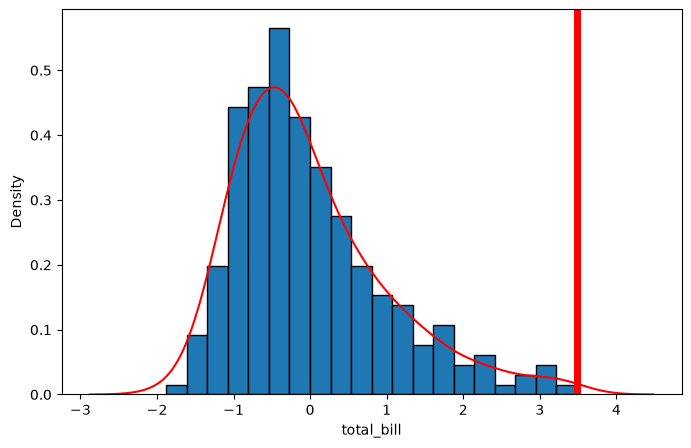

In [63]:
# zscore -plot ( plt.hist + sns.kde )
zscore = (total_bill-total_bill.mean())/total_bill.std()
zsc_ab = sorted(np.abs(zscore),reverse=True)
print(["{:.1f}".format(x) for x in zsc_ab if x>2])
plt.figure(figsize=(8,5))
plt.hist(zscore,density=True,bins=20,edgecolor="black")
sns.kdeplot(zscore,zorder=2,color="red")
plt.axvline(np.array(zsc_ab).max(),lw=5,color="red")
plt.show()